In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# Switzerland

In [2]:
cantons = [
    "Aargau", "Appenzell Ausserrhoden", "Appenzell Innerrhoden", "Basel-Landschaft", "Basel-Stadt",
    "Bern", "Fribourg", "Geneva", "Glarus", "Graubünden", "Jura", "Lucerne", "Neuchâtel", "Nidwalden",
    "Obwalden", "Schaffhausen", "Schwyz", "Solothurn", "St. Gallen", "Thurgau", "Ticino", "Uri",
    "Valais", "Vaud", "Zug", "Zurich"
]

years = [2030, 2040, 2050]

In [3]:
Path("/home/yhaddad/speed2zero/website/").mkdir(parents=True, exist_ok=True)

## Yearly

### Temperature

In [4]:
data = {
    "time": [],
    "area": [],
    "location": [],
    "temperature": [],
    "unit": [],
    "model": []
}

models = ["wet", "dry"]

for year in years:
    for canton in cantons:
        anomaly_base = 1.0 + years.index(year) * 0.7
        noise = np.random.uniform(-0.2, 0.2)

        # Calculate both model values
        wet_current = round(anomaly_base + noise - 0.3, 1)
        dry_current = round(anomaly_base + noise + 0.3, 1)

        # Min/max represents total model spread
        min_val = round(min(wet_current, dry_current) * 0.9, 1)
        max_val = round(max(wet_current, dry_current) * 1.1, 1)

        for model in models:
            current = wet_current if model == "wet" else dry_current

            data["time"].append(f"{year}-12-31T23:00")
            data["area"].append("switzerland")
            data["location"].append(canton)
            data["temperature"].append([min_val, current, max_val])
            data["unit"].append("c")
            data["model"].append(model)

df = pd.DataFrame(data)
df.to_csv("/home/yhaddad/speed2zero/website/switzerland_temperature_per_canton_yearly.csv", index=False)

In [5]:
data = {
    "time": [],
    "area": [],
    "temperature": [],
    "unit": [],
    "model": []
}

models = ["wet", "dry"]

for year in years:
    anomaly_base = 1.0 + years.index(year) * 0.7
    noise = np.random.uniform(-0.2, 0.2)

    # Calculate both model values
    wet_current = round(anomaly_base + noise - 0.3, 1)
    dry_current = round(anomaly_base + noise + 0.3, 1)

    # Min/max represents total model spread
    min_val = round(min(wet_current, dry_current) * 0.9, 1)
    max_val = round(max(wet_current, dry_current) * 1.1, 1)

    for model in models:
        current = wet_current if model == "wet" else dry_current

        data["time"].append(f"{year}-12-31T23:00")
        data["area"].append("switzerland")
        data["temperature"].append([min_val, current, max_val])
        data["unit"].append("c")
        data["model"].append(model)

df = pd.DataFrame(data)
df.to_csv("/home/yhaddad/speed2zero/website/switzerland_temperature_yearly.csv", index=False)


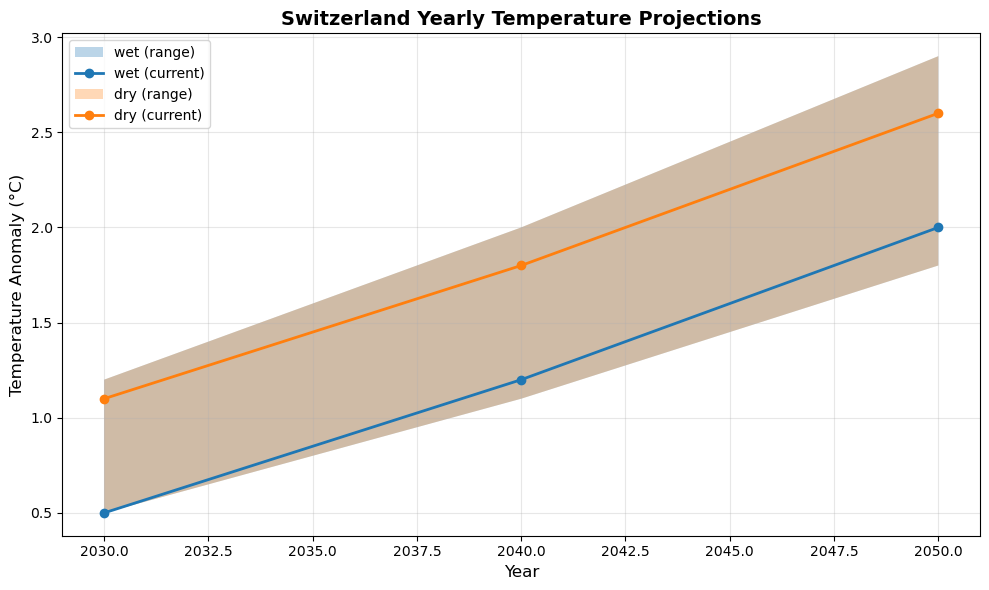

In [6]:
# Plot Switzerland Yearly Temperature
fig, ax = plt.subplots(figsize=(10, 6))

for model in ["wet", "dry"]:
    model_data = df[df["model"] == model].copy()
    model_data["year"] = model_data["time"].str[:4].astype(int)
    model_data = model_data.sort_values("year")

    # Extract min, current, max from arrays
    temps = np.array([t for t in model_data["temperature"]])
    min_vals = temps[:, 0]
    current_vals = temps[:, 1]
    max_vals = temps[:, 2]

    years_plot = model_data["year"].values

    # Plot with fill_between for uncertainty
    ax.fill_between(years_plot, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(years_plot, current_vals, marker='o', linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Temperature Anomaly (°C)", fontsize=12)
ax.set_title("Switzerland Yearly Temperature Projections", fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### PV, Wind Power

In [7]:
# Dummy percentage change data for PV and wind power
pv_proj = {2030: 3, 2040: 5, 2050: 8}
wind_proj = {2030: 3, 2040: 5, 2050: 8}
# Dummy percentage change data for hydropower
hydro_proj = {2030: -1, 2040: 0, 2050: -2}

models = ["wet", "dry"]

yearly_percentage_change = []

for year in years:
    # Generate noise once per year
    pv_noise = np.random.uniform(-2, 2)
    wind_noise = np.random.uniform(-2, 2)
    hydro_noise = np.random.uniform(-1, 1)

    # Calculate values for both models
    pv_wet = round(pv_proj[year] + pv_noise - 2)
    pv_dry = round(pv_proj[year] + pv_noise + 2)
    wind_wet = round(wind_proj[year] + np.random.uniform(-1, 1))
    wind_dry = round(wind_proj[year] + np.random.uniform(-1, 1))
    hydro_wet = round(hydro_proj[year] + hydro_noise + 2)
    hydro_dry = round(hydro_proj[year] + hydro_noise - 2)

    # Min/max represents total model spread
    pv_min = round(min(pv_wet, pv_dry) * 0.7)
    pv_max = round(max(pv_wet, pv_dry) * 1.3)
    wind_min = round(wind_wet * 0.7)  # Same for both models
    wind_max = round(wind_wet * 1.3)
    hydro_min = round(min(hydro_wet, hydro_dry) * 0.7)
    hydro_max = round(max(hydro_wet, hydro_dry) * 1.3)

    for model in models:
        pv_current = pv_wet if model == "wet" else pv_dry
        wind_current = wind_wet if model == "wet" else wind_dry
        hydro_current = hydro_wet if model == "wet" else hydro_dry

        # PV
        yearly_percentage_change.append({
            "time": f"{year}-12-31T23:00",
            "area": "switzerland",
            "tech": "pv",
            "percentage_change": [pv_min, pv_current, pv_max],
            "unit": "%",
            "model": model
        })
        # Wind
        yearly_percentage_change.append({
            "time": f"{year}-12-31T23:00",
            "area": "switzerland",
            "tech": "wind",
            "percentage_change": [wind_min, wind_current, wind_max],
            "unit": "%",
            "model": model
        })
        # Hydro
        yearly_percentage_change.append({
            "time": f"{year}-12-31T23:00",
            "area": "switzerland",
            "tech": "hydro",
            "percentage_change": [hydro_min, hydro_current, hydro_max],
            "unit": "%",
            "model": model
        })

# Convert to DataFrame
yearly_percentage_change_df = pd.DataFrame(yearly_percentage_change)

# Save to CSV
yearly_percentage_change_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_percentage_change_yearly.csv", index=False)

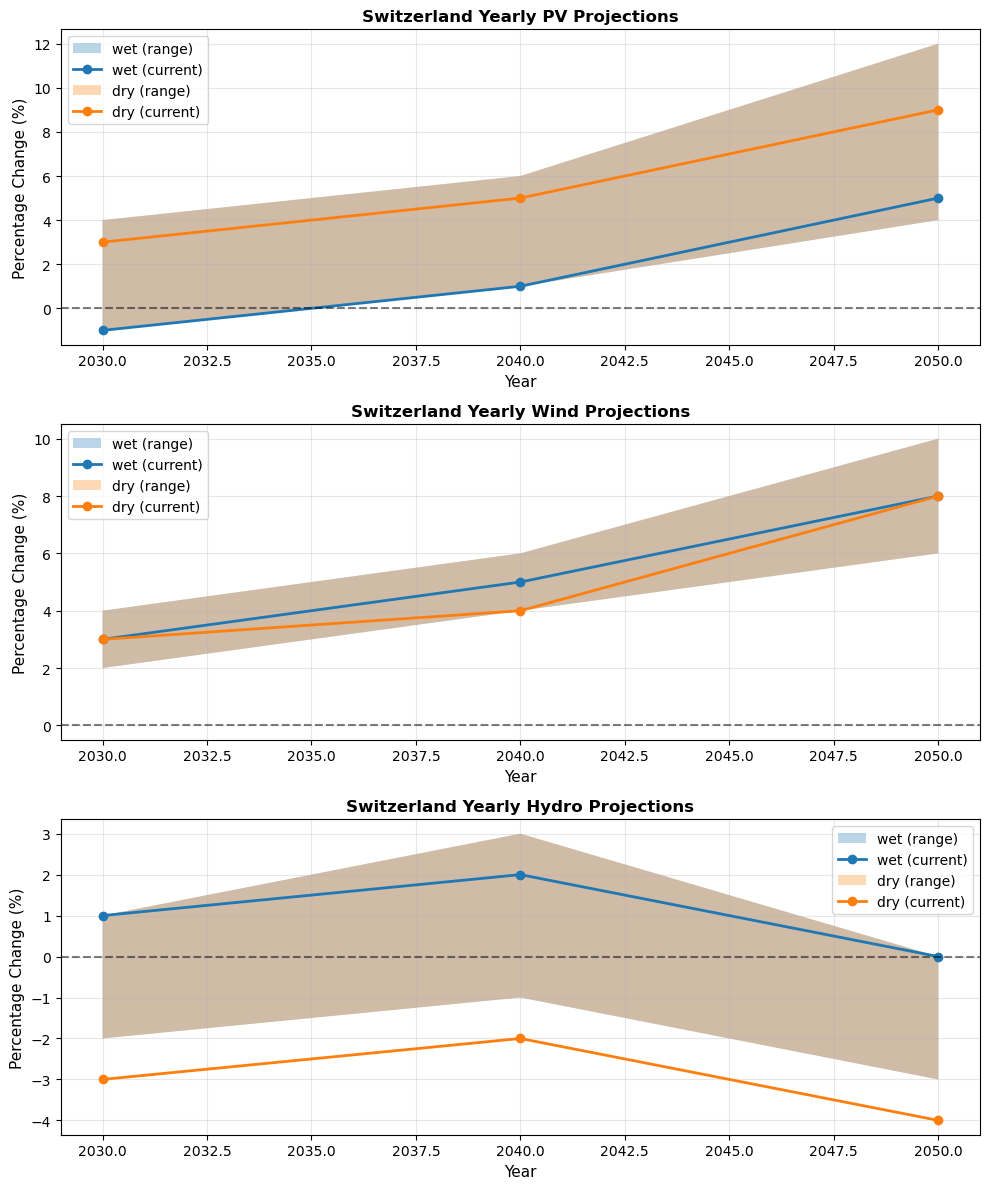

In [8]:
# Plot Switzerland Yearly Renewable Energy
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
techs = ['pv', 'wind', 'hydro']
titles = ['PV', 'Wind', 'Hydro']

for idx, (tech, title) in enumerate(zip(techs, titles)):
    ax = axes[idx]

    for model in ["wet", "dry"]:
        model_data = yearly_percentage_change_df[(yearly_percentage_change_df["model"] == model) &
                                                   (yearly_percentage_change_df["tech"] == tech)].copy()
        model_data["year"] = model_data["time"].str[:4].astype(int)
        model_data = model_data.sort_values("year")

        # Extract min, current, max from arrays
        values = np.array([v for v in model_data["percentage_change"]])
        min_vals = values[:, 0]
        current_vals = values[:, 1]
        max_vals = values[:, 2]

        years_plot = model_data["year"].values

        # Plot with fill_between for uncertainty
        ax.fill_between(years_plot, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
        ax.plot(years_plot, current_vals, marker='o', linewidth=2, label=f'{model} (current)')

    ax.set_xlabel("Year", fontsize=11)
    ax.set_ylabel("Percentage Change (%)", fontsize=11)
    ax.set_title(f"Switzerland Yearly {title} Projections", fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [9]:
# Baseline projections for HDD and CDD percentage changes
# HDD decreases due to warming, CDD increases
hdd_proj = {2030: -5, 2040: -8, 2050: -12}  # percent change
cdd_proj = {2030: 10, 2040: 15, 2050: 20}   # percent change

models = ["wet", "dry"]

yearly_hdd_cdd = []

for year in years:
    # Generate noise once per year
    hdd_noise = np.random.uniform(-1, 1)
    cdd_noise = np.random.uniform(-1, 1)

    # Calculate values for both models (HDD is negative, CDD is positive)
    hdd_wet = min(0, round(hdd_proj[year] + 2 + hdd_noise))  # wet: less decrease
    hdd_dry = min(0, round(hdd_proj[year] - 2 + hdd_noise))  # dry: more decrease
    cdd_wet = max(0, round(cdd_proj[year] - 3 + cdd_noise))  # wet: less increase
    cdd_dry = max(0, round(cdd_proj[year] + 3 + cdd_noise))  # dry: more increase

    # Min/max represents total model spread
    hdd_min = round(min(hdd_wet, hdd_dry) * 1.3)  # More negative
    hdd_max = round(max(hdd_wet, hdd_dry) * 0.7)  # Less negative
    cdd_min = round(min(cdd_wet, cdd_dry) * 0.7)  # Less positive
    cdd_max = round(max(cdd_wet, cdd_dry) * 1.3)  # More positive

    for model in models:
        hdd_current = hdd_wet if model == "wet" else hdd_dry
        cdd_current = cdd_wet if model == "wet" else cdd_dry

        yearly_hdd_cdd.append({
            "time": f"{year}-12-31T23:00",
            "area": "switzerland",
            "heating_degree_days": [hdd_min, hdd_current, hdd_max],
            "cooling_degree_days": [cdd_min, cdd_current, cdd_max],
            "unit": "%",
            "model": model
        })

# Convert to DataFrame
yearly_hdd_cdd_df = pd.DataFrame(yearly_hdd_cdd)

# Save to CSV
yearly_hdd_cdd_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_hdd_cdd_yearly.csv", index=False)

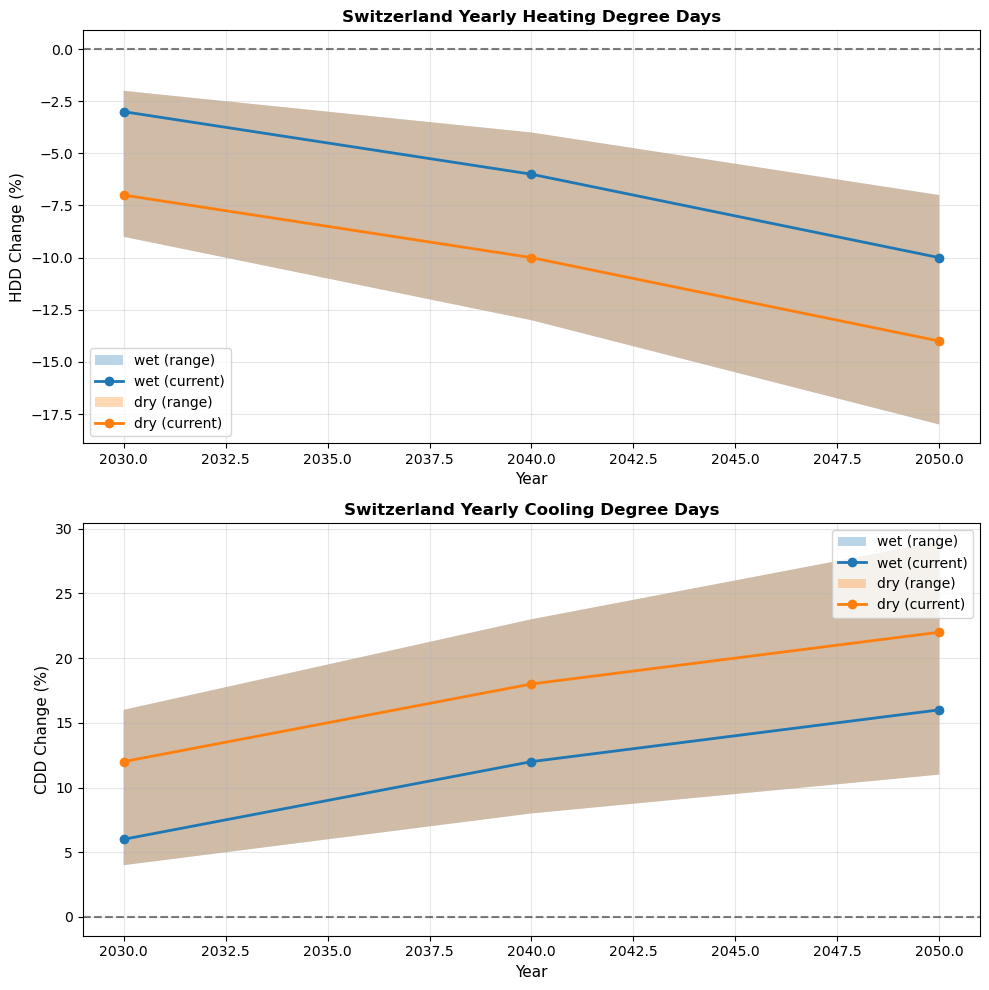

In [10]:
# Plot Switzerland Yearly HDD and CDD
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# HDD subplot
ax = axes[0]
for model in ["wet", "dry"]:
    model_data = yearly_hdd_cdd_df[yearly_hdd_cdd_df["model"] == model].copy()
    model_data["year"] = model_data["time"].str[:4].astype(int)
    model_data = model_data.sort_values("year")

    # Extract min, current, max from arrays
    hdd_values = np.array([h for h in model_data["heating_degree_days"]])
    min_vals = hdd_values[:, 0]
    current_vals = hdd_values[:, 1]
    max_vals = hdd_values[:, 2]

    years_plot = model_data["year"].values

    # Plot with fill_between for uncertainty
    ax.fill_between(years_plot, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(years_plot, current_vals, marker='o', linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("HDD Change (%)", fontsize=11)
ax.set_title("Switzerland Yearly Heating Degree Days", fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

# CDD subplot
ax = axes[1]
for model in ["wet", "dry"]:
    model_data = yearly_hdd_cdd_df[yearly_hdd_cdd_df["model"] == model].copy()
    model_data["year"] = model_data["time"].str[:4].astype(int)
    model_data = model_data.sort_values("year")

    # Extract min, current, max from arrays
    cdd_values = np.array([c for c in model_data["cooling_degree_days"]])
    min_vals = cdd_values[:, 0]
    current_vals = cdd_values[:, 1]
    max_vals = cdd_values[:, 2]

    years_plot = model_data["year"].values

    # Plot with fill_between for uncertainty
    ax.fill_between(years_plot, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(years_plot, current_vals, marker='o', linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("CDD Change (%)", fontsize=11)
ax.set_title("Switzerland Yearly Cooling Degree Days", fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Monthly

### PV, Wind Power

In [11]:
# Dummy percentage change data for PV, wind power, and hydropower
hydro_proj = {2030: 1, 2040: 0, 2050: -1}
pv_proj = {2030: 3, 2040: 5, 2050: 8}
wind_proj = {2030: 3, 2040: 5, 2050: 8}

models = ["wet", "dry"]

monthly_percentage_change = []
months = range(1, 13)  # January to December

for year in years:
    for month in months:
        last_day = pd.Period(f"{year}-{month}").days_in_month

        # Generate noise once per month
        seasonal_factor = np.sin((month - 1) / 12 * 2 * np.pi)
        pv_noise = np.random.uniform(-2, 2) + seasonal_factor
        wind_noise = np.random.uniform(-2, 2) + 0.5 * seasonal_factor
        hydro_noise = np.random.uniform(-1, 1)

        # Calculate values for both models
        pv_wet = round(pv_proj[year] + pv_noise - 2)
        pv_dry = round(pv_proj[year] + pv_noise + 2)
        wind_wet = round(wind_proj[year] + np.random.uniform(-2, 2) + 0.5 * seasonal_factor)
        wind_dry = round(wind_proj[year] + np.random.uniform(-2, 2) + 0.5 * seasonal_factor)
        hydro_wet = round(hydro_proj[year] + hydro_noise + 2)
        hydro_dry = round(hydro_proj[year] + hydro_noise - 2)

        # Min/max represents total model spread
        pv_min = round(min(pv_wet, pv_dry) * 0.7)
        pv_max = round(max(pv_wet, pv_dry) * 1.3)
        wind_min = round(wind_wet * 0.7)
        wind_max = round(wind_wet * 1.3)
        hydro_min = round(min(hydro_wet, hydro_dry) * 0.7)
        hydro_max = round(max(hydro_wet, hydro_dry) * 1.3)

        for model in models:
            pv_current = pv_wet if model == "wet" else pv_dry
            wind_current = wind_wet if model == "wet" else wind_dry
            hydro_current = hydro_wet if model == "wet" else hydro_dry

            # PV
            monthly_percentage_change.append({
                "time": f"{year}-{month:02d}-{last_day}T23:00",
                "area": "switzerland",
                "tech": "pv",
                "percentage_change": [pv_min, pv_current, pv_max],
                "unit": "%",
                "model": model
            })
            # Wind
            monthly_percentage_change.append({
                "time": f"{year}-{month:02d}-{last_day}T23:00",
                "area": "switzerland",
                "tech": "wind",
                "percentage_change": [wind_min, wind_current, wind_max],
                "unit": "%",
                "model": model
            })
            # Hydro
            monthly_percentage_change.append({
                "time": f"{year}-{month:02d}-{last_day}T23:00",
                "area": "switzerland",
                "tech": "hydro",
                "percentage_change": [hydro_min, hydro_current, hydro_max],
                "unit": "%",
                "model": model
            })

# Convert to DataFrame
monthly_percentage_change_df = pd.DataFrame(monthly_percentage_change)

# Save to CSV
monthly_percentage_change_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_percentage_change_monthly.csv", index=False)

# Convert to DataFrame# Save to CSV

monthly_percentage_change_df = pd.DataFrame(monthly_percentage_change)

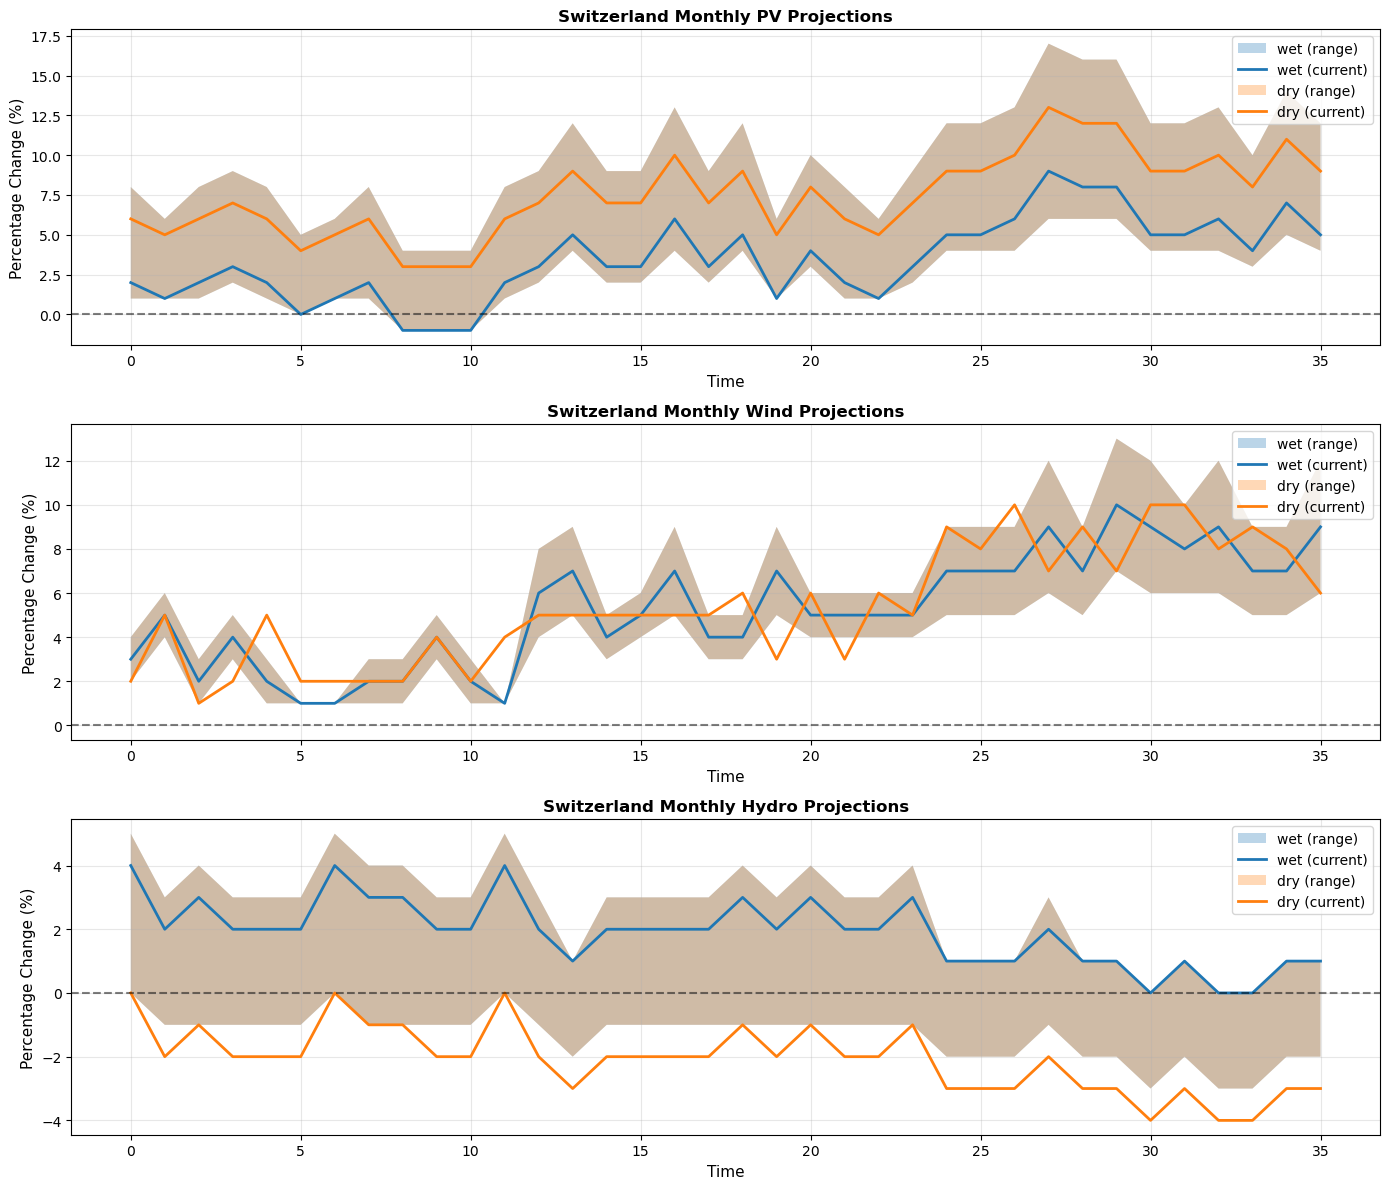

In [12]:
# Plot Switzerland Monthly Renewable Energy
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
techs = ['pv', 'wind', 'hydro']
titles = ['PV', 'Wind', 'Hydro']

for idx, (tech, title) in enumerate(zip(techs, titles)):
    ax = axes[idx]

    for model in ["wet", "dry"]:
        model_data = monthly_percentage_change_df[(monthly_percentage_change_df["model"] == model) &
                                                    (monthly_percentage_change_df["tech"] == tech)].copy()
        model_data["datetime"] = pd.to_datetime(model_data["time"])
        model_data = model_data.sort_values("datetime")

        # Extract min, current, max from arrays
        values = np.array([v for v in model_data["percentage_change"]])
        min_vals = values[:, 0]
        current_vals = values[:, 1]
        max_vals = values[:, 2]

        x_values = range(len(model_data))

        # Plot with fill_between for uncertainty
        ax.fill_between(x_values, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
        ax.plot(x_values, current_vals, linewidth=2, label=f'{model} (current)')

    ax.set_xlabel("Time", fontsize=11)
    ax.set_ylabel("Percentage Change (%)", fontsize=11)
    ax.set_title(f"Switzerland Monthly {title} Projections", fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Heating and Cooling Degree Days

In [13]:
base_temp = 18  # base temperature in Celsius

months = range(1, 13)

# Baseline projections for HDD and CDD percentage changes
# HDD decreases due to warming, CDD increases
hdd_proj = {2030: -5, 2040: -8, 2050: -12}  # percent change
cdd_proj = {2030: 10, 2040: 15, 2050: 20}   # percent change

# Monthly variation factors - HDD is higher in winter, CDD is higher in summer
# Normalized patterns (will be scaled by yearly projections)
hdd_monthly_pattern = [1.5, 1.4, 1.2, 0.8, 0.4, 0.1, 0.0, 0.0, 0.3, 0.7, 1.1, 1.4]  # Jan to Dec
cdd_monthly_pattern = [0.0, 0.0, 0.0, 0.1, 0.4, 0.9, 1.5, 1.4, 0.7, 0.2, 0.0, 0.0]  # Jan to Dec

models = ["wet", "dry"]

data = {
    "time": [],
    "area": [],
    "heating_degree_days": [],
    "cooling_degree_days": [],
    "unit": [],
    "model": []
}

for year in years:
    for i, month in enumerate(months):
        # Generate noise once per month
        hdd_noise = np.random.uniform(-1, 1)
        cdd_noise = np.random.uniform(-1, 1)

        # Apply monthly pattern to the yearly baseline
        hdd_seasonal = hdd_proj[year] * hdd_monthly_pattern[i]
        cdd_seasonal = cdd_proj[year] * cdd_monthly_pattern[i]

        # Calculate values for both models (HDD is negative, CDD is positive)
        hdd_wet = min(0, round(hdd_seasonal + 2 + hdd_noise))  # wet: less decrease
        hdd_dry = min(0, round(hdd_seasonal - 2 + hdd_noise))  # dry: more decrease
        cdd_wet = max(0, round(cdd_seasonal - 3 + cdd_noise))  # wet: less increase
        cdd_dry = max(0, round(cdd_seasonal + 3 + cdd_noise))  # dry: more increase

        # Min/max represents total model spread
        hdd_min = round(min(hdd_wet, hdd_dry) * 1.3)  # More negative
        hdd_max = round(max(hdd_wet, hdd_dry) * 0.7)  # Less negative
        cdd_min = round(min(cdd_wet, cdd_dry) * 0.7)  # Less positive
        cdd_max = round(max(cdd_wet, cdd_dry) * 1.3)  # More positive

        for model in models:
            hdd_current = hdd_wet if model == "wet" else hdd_dry
            cdd_current = cdd_wet if model == "wet" else cdd_dry

            last_day = pd.Period(f"{year}-{month}").days_in_month
            data["time"].append(f"{year}-{month:02d}-{last_day}T23:00")
            data["area"].append("switzerland")
            data["heating_degree_days"].append([hdd_min, hdd_current, hdd_max])
            data["cooling_degree_days"].append([cdd_min, cdd_current, cdd_max])
            data["unit"].append("%")
            data["model"].append(model)

national_hdd_cdd_df = pd.DataFrame(data)
national_hdd_cdd_df.to_csv("/home/yhaddad/speed2zero/website/switzerland_hdd_cdd_monthly.csv", index=False)

In [14]:
national_hdd_cdd_df

,time,area,heating_degree_days,cooling_degree_days,unit,model
0,2030-01-31T23:00,switzerland,"[-12, -5, -4]","[0, 0, 4]",%,wet
1,2030-01-31T23:00,switzerland,"[-12, -9, -4]","[0, 3, 4]",%,dry
2,2030-02-28T23:00,switzerland,"[-12, -5, -4]","[0, 0, 4]",%,wet
3,2030-02-28T23:00,switzerland,"[-12, -9, -4]","[0, 3, 4]",%,dry
4,2030-03-31T23:00,switzerland,"[-9, -3, -2]","[0, 0, 4]",%,wet
...,...,...,...,...,...,...
67,2050-10-31T23:00,switzerland,"[-13, -10, -4]","[1, 7, 9]",%,dry
68,2050-11-30T23:00,switzerland,"[-20, -11, -8]","[0, 0, 3]",%,wet
69,2050-11-30T23:00,switzerland,"[-20, -15, -8]","[0, 2, 3]",%,dry
70,2050-12-31T23:00,switzerland,"[-25, -15, -10]","[0, 0, 3]",%,wet


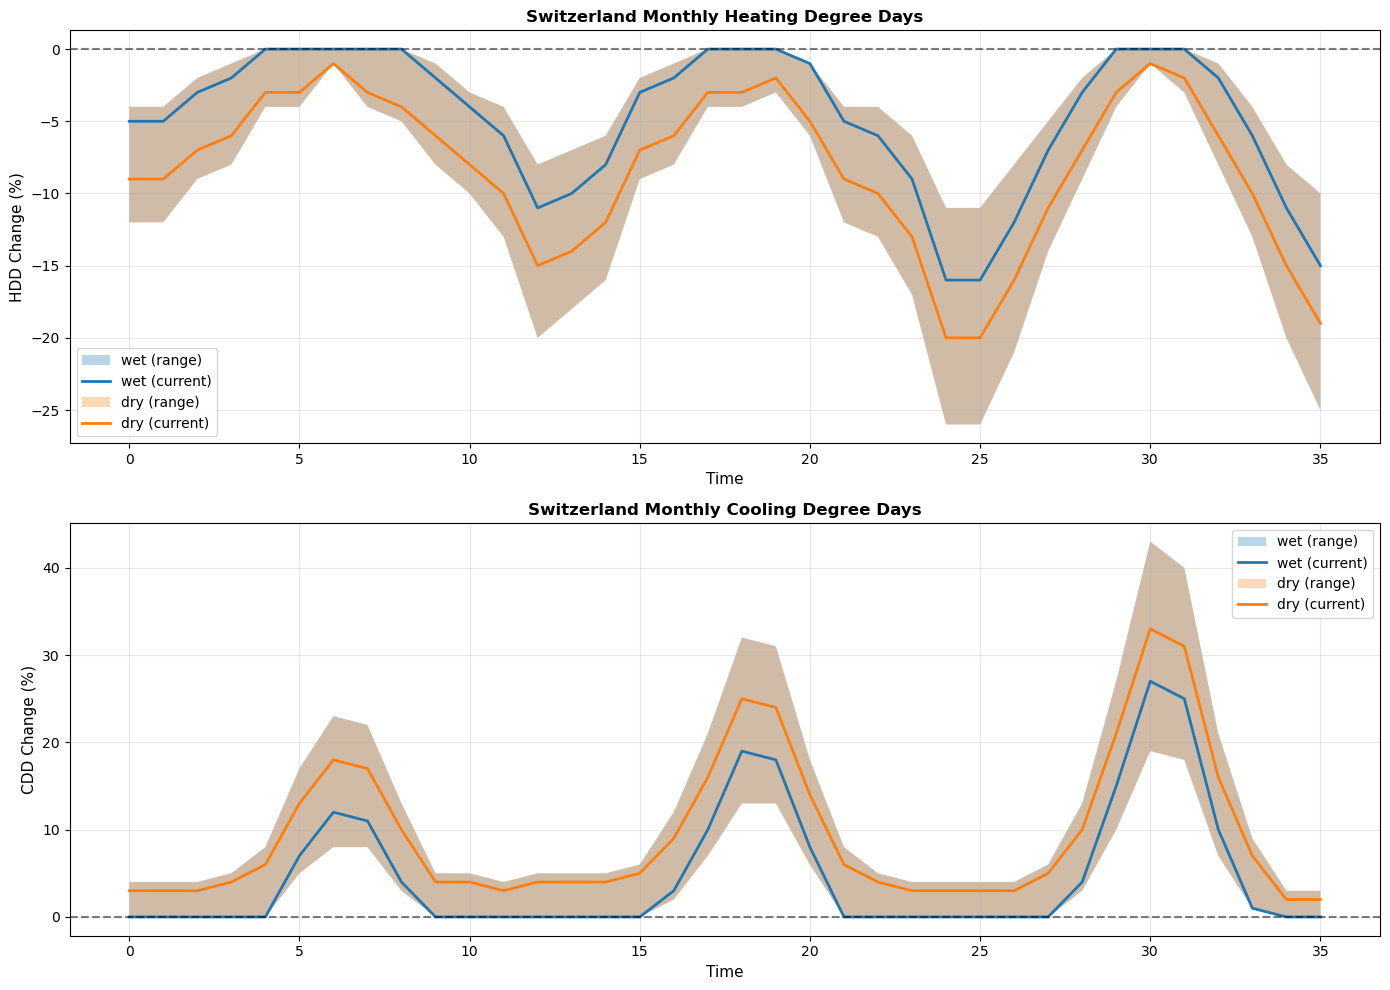

In [15]:
# Plot Switzerland Monthly HDD and CDD
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# HDD subplot
ax = axes[0]
for model in ["wet", "dry"]:
    model_data = national_hdd_cdd_df[national_hdd_cdd_df["model"] == model].copy()
    model_data["datetime"] = pd.to_datetime(model_data["time"])
    model_data = model_data.sort_values("datetime")

    # Extract min, current, max from arrays
    hdd_values = np.array([h for h in model_data["heating_degree_days"]])
    min_vals = hdd_values[:, 0]
    current_vals = hdd_values[:, 1]
    max_vals = hdd_values[:, 2]

    x_values = range(len(model_data))

    # Plot with fill_between for uncertainty
    ax.fill_between(x_values, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(x_values, current_vals, linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Time", fontsize=11)
ax.set_ylabel("HDD Change (%)", fontsize=11)
ax.set_title("Switzerland Monthly Heating Degree Days", fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

# CDD subplot
ax = axes[1]
for model in ["wet", "dry"]:
    model_data = national_hdd_cdd_df[national_hdd_cdd_df["model"] == model].copy()
    model_data["datetime"] = pd.to_datetime(model_data["time"])
    model_data = model_data.sort_values("datetime")

    # Extract min, current, max from arrays
    cdd_values = np.array([c for c in model_data["cooling_degree_days"]])
    min_vals = cdd_values[:, 0]
    current_vals = cdd_values[:, 1]
    max_vals = cdd_values[:, 2]

    x_values = range(len(model_data))

    # Plot with fill_between for uncertainty
    ax.fill_between(x_values, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(x_values, current_vals, linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Time", fontsize=11)
ax.set_ylabel("CDD Change (%)", fontsize=11)
ax.set_title("Switzerland Monthly Cooling Degree Days", fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Europe

In [16]:
EUROPEAN_COUNTRIES = [
    "Albania",
    "Austria",
    "Bosnia and Herzegovina",
    "Belgium",
    "Bulgaria",
    "Switzerland",
    "Czech Republic",
    "Germany",
    "Denmark",
    "Estonia",
    "Spain",
    "Finland",
    "France",
    "Greece",
    "Croatia",
    "Hungary",
    "Ireland",
    "Italy",  # several bidding zones
    "Lithuania",
    "Latvia",
    "Montenegro",
    "Macedonia",
    "Netherlands",
    "Norway",  # several bidding zones
    "Poland",
    "Portugal",
    "Romania",
    "Serbia",
    "Sweden",  # several bidding zones
    "Slovenia",
    "Slovakia",
    "United Kingdom",
]
years = [2030, 2040, 2050]

## Yearly

## Temperature

In [17]:
data = {
    "time": [],
    "area": [],
    "location": [],
    "temperature": [],
    "unit": [],
    "model": []
}

models = ["wet", "dry"]

for i, year in enumerate(years):
    # Set anomaly baseline and increment (e.g., 1.0°C in 2030, 1.7°C in 2040, 2.4°C in 2050)
    anomaly_base = 1.0 + i * 0.7
    for country in EUROPEAN_COUNTRIES:
        noise = np.random.uniform(-0.2, 0.2)

        # Calculate both model values
        wet_current = round(anomaly_base + noise - 0.3, 1)
        dry_current = round(anomaly_base + noise + 0.3, 1)

        # Min/max represents total model spread
        min_val = round(min(wet_current, dry_current) * 0.9, 1)
        max_val = round(max(wet_current, dry_current) * 1.1, 1)

        for model in models:
            current = wet_current if model == "wet" else dry_current

            data["time"].append(f"{year}-12-31T23:00")
            data["area"].append("europe")
            data["location"].append(country)
            data["temperature"].append([min_val, current, max_val])

            data["unit"].append("c")

            data["model"].append(model)
df = pd.DataFrame(data)
df.to_csv("/home/yhaddad/speed2zero/website/europe_temperature_per_country_yearly.csv", index=False)

In [18]:
data = {
    "time": [],
    "area": [],
    "temperature": [],
    "unit": [],
    "model": []
}

models = ["wet", "dry"]

for i, year in enumerate(years):
    # Set anomaly baseline and increment (e.g., 1.5°C in 2030, 2.2°C in 2040, 2.9°C in 2050)
    anomaly_base = 1.5 + i * 0.7
    noise = np.random.uniform(-0.2, 0.2)

    # Calculate both model values
    wet_current = round(anomaly_base + noise - 0.3, 1)
    dry_current = round(anomaly_base + noise + 0.3, 1)

    # Min/max represents total model spread
    min_val = round(min(wet_current, dry_current) * 0.9, 1)
    max_val = round(max(wet_current, dry_current) * 1.1, 1)

    for model in models:
        current = wet_current if model == "wet" else dry_current

        data["time"].append(f"{year}-12-31T23:00")
        data["area"].append("europe")
        data["temperature"].append([min_val, current, max_val])

        data["unit"].append("c")

        data["model"].append(model)

df = pd.DataFrame(data)
df.to_csv("/home/yhaddad/speed2zero/website/europe_temperature_yearly.csv", index=False)


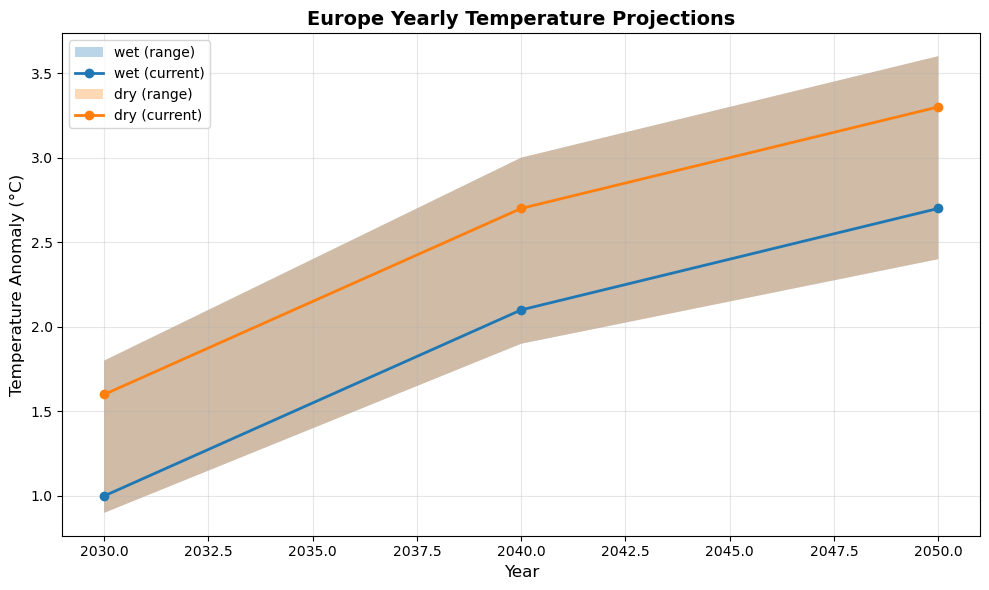

In [19]:
# Plot Europe Yearly Temperature
fig, ax = plt.subplots(figsize=(10, 6))

for model in ["wet", "dry"]:
    model_data = df[df["model"] == model].copy()
    model_data["year"] = model_data["time"].str[:4].astype(int)
    model_data = model_data.sort_values("year")

    # Extract min, current, max from arrays
    temps = np.array([t for t in model_data["temperature"]])
    min_vals = temps[:, 0]
    current_vals = temps[:, 1]
    max_vals = temps[:, 2]

    years_plot = model_data["year"].values

    # Plot with fill_between for uncertainty
    ax.fill_between(years_plot, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(years_plot, current_vals, marker='o', linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Temperature Anomaly (°C)", fontsize=12)
ax.set_title("Europe Yearly Temperature Projections", fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### PV, Wind Power

In [20]:
# Dummy percentage change data for PV and wind power
pv_proj = {2030: 3, 2040: 5, 2050: 8}
wind_proj = {2030: 3, 2040: 5, 2050: 8}
# Dummy percentage change data for hydropower
hydro_proj = {2030: -2, 2040: -3, 2050: -4}

models = ["wet", "dry"]

yearly_percentage_change = []

for year in years:
    for model in models:
        # Model-specific adjustments: dry = higher PV, lower hydro; wet = lower PV, higher hydro
        pv_model_adj = 2 if model == "dry" else -2
        hydro_model_adj = -2 if model == "dry" else 2

        # Add random noise between -2% and +2% for each canton/month
        pv_noise = np.random.uniform(-2, 2)
        wind_noise = np.random.uniform(-2, 2)
        hydro_noise = np.random.uniform(-1, 1)
        pv_current = round(pv_proj[year] + pv_noise + pv_model_adj)
        wind_current = round(wind_proj[year] + wind_noise)
        hydro_current = round(hydro_proj[year] + hydro_noise + hydro_model_adj)

        pv_min = round(pv_current * 0.6)
        pv_max = round(pv_current * 1.4)
        wind_min = round(wind_current * 0.6)
        wind_max = round(wind_current * 1.4)
        hydro_min = round(hydro_current * 0.6)
        hydro_max = round(hydro_current * 1.4)

        # PV
        yearly_percentage_change.append({
            "time": f"{year}-12-31T23:00",
            "area": "europe",
            "tech": "pv",
            "percentage_change": [pv_min, pv_current, pv_max],
            "unit": "%",
            "model": model
        })
        # Wind
        yearly_percentage_change.append({
            "time": f"{year}-12-31T23:00",
            "area": "europe",
            "tech": "wind",
            "percentage_change": [wind_min, wind_current, wind_max],
            "unit": "%",
            "model": model
        })
        # Hydro
        yearly_percentage_change.append({
            "time": f"{year}-12-31T23:00",
            "area": "europe",
            "tech": "hydro",
            "percentage_change": [hydro_min, hydro_current, hydro_max],
            "unit": "%",
            "model": model
        })

# Convert to DataFrame
yearly_percentage_change_df = pd.DataFrame(yearly_percentage_change)

# Save to CSV
yearly_percentage_change_df.to_csv("/home/yhaddad/speed2zero/website/europe_percentage_change_yearly.csv", index=False)

In [21]:
yearly_percentage_change_df

,time,area,tech,percentage_change,unit,model
0,2030-12-31T23:00,europe,pv,"[1, 1, 1]",%,wet
1,2030-12-31T23:00,europe,wind,"[1, 2, 3]",%,wet
2,2030-12-31T23:00,europe,hydro,"[0, 0, 0]",%,wet
3,2030-12-31T23:00,europe,pv,"[2, 4, 6]",%,dry
4,2030-12-31T23:00,europe,wind,"[3, 5, 7]",%,dry
5,2030-12-31T23:00,europe,hydro,"[-3, -5, -7]",%,dry
6,2040-12-31T23:00,europe,pv,"[1, 2, 3]",%,wet
7,2040-12-31T23:00,europe,wind,"[3, 5, 7]",%,wet
8,2040-12-31T23:00,europe,hydro,"[-1, -1, -1]",%,wet
9,2040-12-31T23:00,europe,pv,"[4, 7, 10]",%,dry


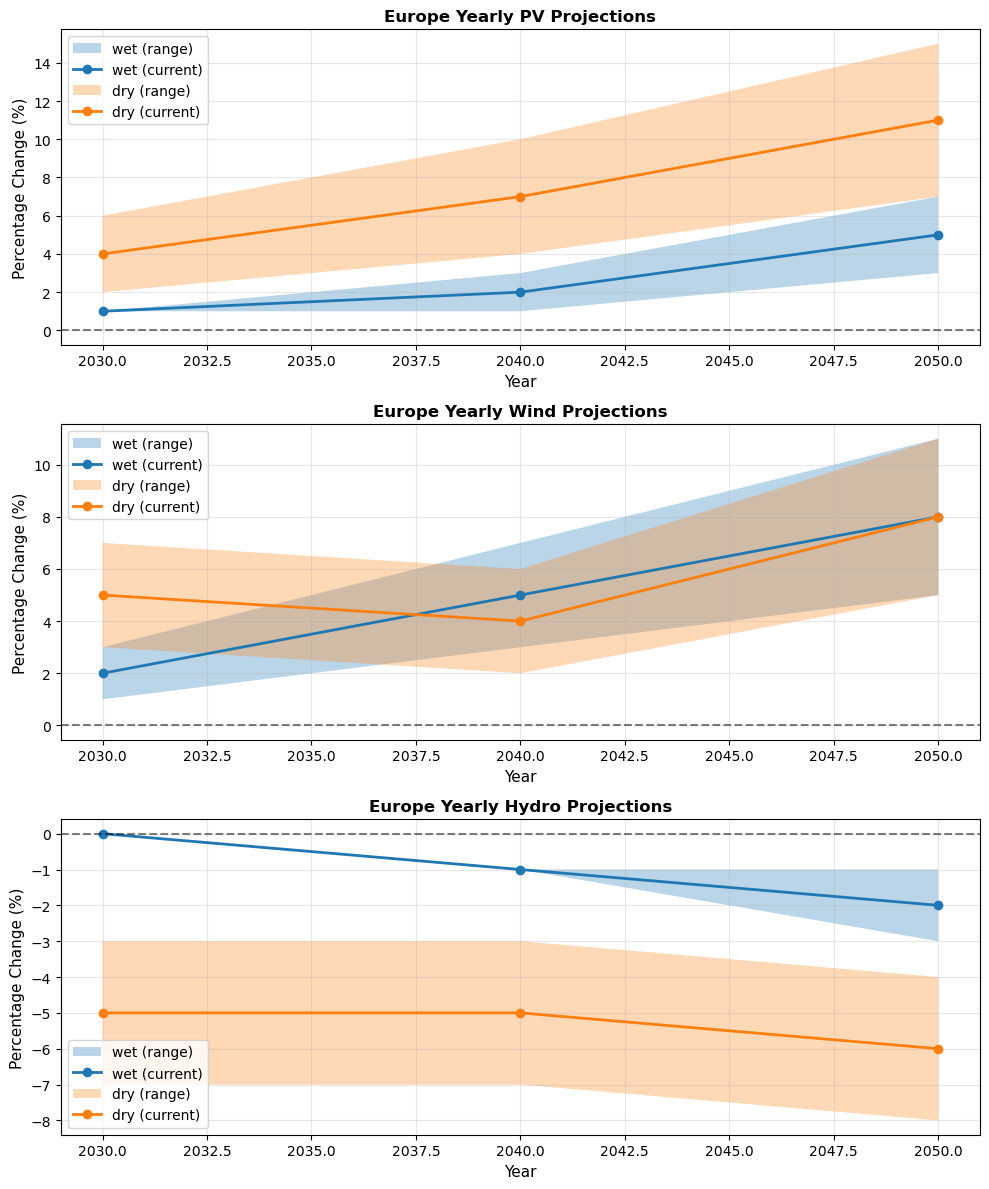

In [22]:
# Plot Europe Yearly Renewable Energy
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
techs = ['pv', 'wind', 'hydro']
titles = ['PV', 'Wind', 'Hydro']

for idx, (tech, title) in enumerate(zip(techs, titles)):
    ax = axes[idx]

    for model in ["wet", "dry"]:
        model_data = yearly_percentage_change_df[(yearly_percentage_change_df["model"] == model) &
                                                   (yearly_percentage_change_df["tech"] == tech)].copy()
        model_data["year"] = model_data["time"].str[:4].astype(int)
        model_data = model_data.sort_values("year")

        # Extract min, current, max from arrays
        values = np.array([v for v in model_data["percentage_change"]])
        min_vals = values[:, 0]
        current_vals = values[:, 1]
        max_vals = values[:, 2]

        years_plot = model_data["year"].values

        # Plot with fill_between for uncertainty
        ax.fill_between(years_plot, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
        ax.plot(years_plot, current_vals, marker='o', linewidth=2, label=f'{model} (current)')

    ax.set_xlabel("Year", fontsize=11)
    ax.set_ylabel("Percentage Change (%)", fontsize=11)
    ax.set_title(f"Europe Yearly {title} Projections", fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [23]:
# Baseline projections for HDD and CDD percentage changes
# HDD decreases due to warming, CDD increases
hdd_proj = {2030: -5, 2040: -8, 2050: -12}  # percent change
cdd_proj = {2030: 10, 2040: 15, 2050: 20}   # percent change

models = ["wet", "dry"]

yearly_hdd_cdd = []

for year in years:
    # Generate noise once per year
    hdd_noise = np.random.uniform(-1, 1)
    cdd_noise = np.random.uniform(-1, 1)

    # Calculate values for both models (HDD is negative, CDD is positive)
    hdd_wet = min(0, round(hdd_proj[year] + 2 + hdd_noise))  # wet: less decrease
    hdd_dry = min(0, round(hdd_proj[year] - 2 + hdd_noise))  # dry: more decrease
    cdd_wet = max(0, round(cdd_proj[year] - 3 + cdd_noise))  # wet: less increase
    cdd_dry = max(0, round(cdd_proj[year] + 3 + cdd_noise))  # dry: more increase

    # Min/max represents total model spread
    hdd_min = round(min(hdd_wet, hdd_dry) * 1.3)  # More negative
    hdd_max = round(max(hdd_wet, hdd_dry) * 0.7)  # Less negative
    cdd_min = round(min(cdd_wet, cdd_dry) * 0.7)  # Less positive
    cdd_max = round(max(cdd_wet, cdd_dry) * 1.3)  # More positive

    for model in models:
        hdd_current = hdd_wet if model == "wet" else hdd_dry
        cdd_current = cdd_wet if model == "wet" else cdd_dry

        yearly_hdd_cdd.append({
            "time": f"{year}-12-31T23:00",
            "area": "europe",
            "heating_degree_days": [hdd_min, hdd_current, hdd_max],
            "cooling_degree_days": [cdd_min, cdd_current, cdd_max],
            "unit": "%",
            "model": model
        })

# Convert to DataFrame
yearly_hdd_cdd_df = pd.DataFrame(yearly_hdd_cdd)

# Save to CSV
yearly_hdd_cdd_df.to_csv("/home/yhaddad/speed2zero/website/europe_hdd_cdd_yearly.csv", index=False)

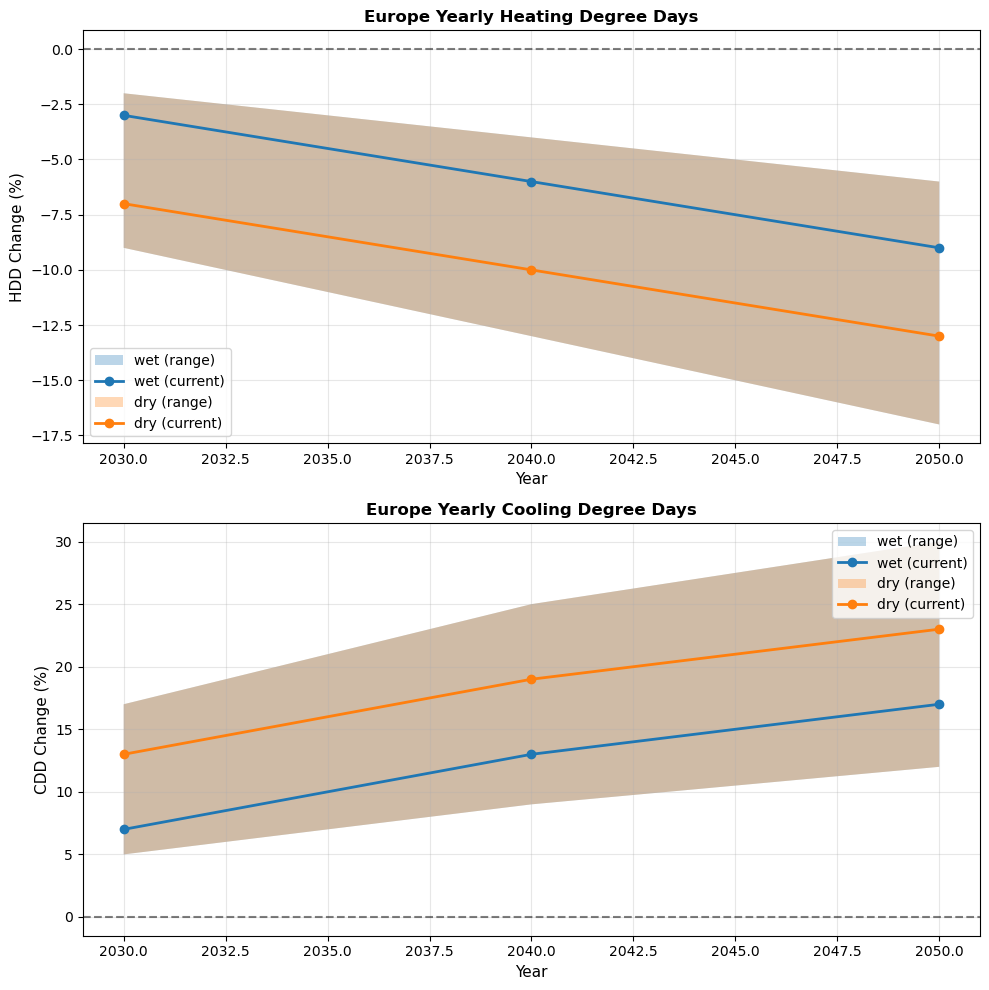

In [24]:
# Plot Europe Yearly HDD and CDD
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# HDD subplot
ax = axes[0]
for model in ["wet", "dry"]:
    model_data = yearly_hdd_cdd_df[yearly_hdd_cdd_df["model"] == model].copy()
    model_data["year"] = model_data["time"].str[:4].astype(int)
    model_data = model_data.sort_values("year")

    # Extract min, current, max from arrays
    hdd_values = np.array([h for h in model_data["heating_degree_days"]])
    min_vals = hdd_values[:, 0]
    current_vals = hdd_values[:, 1]
    max_vals = hdd_values[:, 2]

    years_plot = model_data["year"].values

    # Plot with fill_between for uncertainty
    ax.fill_between(years_plot, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(years_plot, current_vals, marker='o', linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("HDD Change (%)", fontsize=11)
ax.set_title("Europe Yearly Heating Degree Days", fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

# CDD subplot
ax = axes[1]
for model in ["wet", "dry"]:
    model_data = yearly_hdd_cdd_df[yearly_hdd_cdd_df["model"] == model].copy()
    model_data["year"] = model_data["time"].str[:4].astype(int)
    model_data = model_data.sort_values("year")

    # Extract min, current, max from arrays
    cdd_values = np.array([c for c in model_data["cooling_degree_days"]])
    min_vals = cdd_values[:, 0]
    current_vals = cdd_values[:, 1]
    max_vals = cdd_values[:, 2]

    years_plot = model_data["year"].values

    # Plot with fill_between for uncertainty
    ax.fill_between(years_plot, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(years_plot, current_vals, marker='o', linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("CDD Change (%)", fontsize=11)
ax.set_title("Europe Yearly Cooling Degree Days", fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Monthly

### PV, Wind Power

In [25]:
# Dummy percentage change data for PV, wind power, and hydropower
hydro_proj = {2030: 1, 2040: 0, 2050: -1}
pv_proj = {2030: 3, 2040: 5, 2050: 8}
wind_proj = {2030: 3, 2040: 5, 2050: 8}

models = ["wet", "dry"]

monthly_percentage_change = []

for year in years:
    for month in months:
        last_day = pd.Period(f"{year}-{month}").days_in_month

        # Generate noise once per month
        seasonal_factor = np.sin((month - 1) / 12 * 2 * np.pi)
        pv_noise = np.random.uniform(-2, 2) + seasonal_factor
        wind_noise = np.random.uniform(-2, 2) + 0.5 * seasonal_factor
        hydro_noise = np.random.uniform(-1, 1)

        # Calculate values for both models
        pv_wet = round(pv_proj[year] + pv_noise - 2)
        pv_dry = round(pv_proj[year] + pv_noise + 2)
        wind_wet = round(wind_proj[year] + np.random.uniform(-2, 2) + 0.5 * seasonal_factor)
        wind_dry = round(wind_proj[year] + np.random.uniform(-2, 2) + 0.5 * seasonal_factor)
        hydro_wet = round(hydro_proj[year] + hydro_noise + 2)
        hydro_dry = round(hydro_proj[year] + hydro_noise - 2)

        # Min/max represents total model spread
        pv_min = round(min(pv_wet, pv_dry) * 0.7)
        pv_max = round(max(pv_wet, pv_dry) * 1.3)
        wind_min = round(wind_wet * 0.7)
        wind_max = round(wind_wet * 1.3)
        hydro_min = round(min(hydro_wet, hydro_dry) * 0.7)
        hydro_max = round(max(hydro_wet, hydro_dry) * 1.3)

        for model in models:
            pv_current = pv_wet if model == "wet" else pv_dry
            wind_current = wind_wet if model == "wet" else wind_dry
            hydro_current = hydro_wet if model == "wet" else hydro_dry

            # PV
            monthly_percentage_change.append({
                "time": f"{year}-{month:02d}-{last_day}T23:00",
                "area": "europe",
                "tech": "pv",
                "percentage_change": [pv_min, pv_current, pv_max],
                "unit": "%",
                "model": model
            })
            # Wind
            monthly_percentage_change.append({
                "time": f"{year}-{month:02d}-{last_day}T23:00",
                "area": "europe",
                "tech": "wind",
                "percentage_change": [wind_min, wind_current, wind_max],
                "unit": "%",
                "model": model
            })
            # Hydro
            monthly_percentage_change.append({
                "time": f"{year}-{month:02d}-{last_day}T23:00",
                "area": "europe",
                "tech": "hydro",
                "percentage_change": [hydro_min, hydro_current, hydro_max],
                "unit": "%",
                "model": model
            })

monthly_percentage_change_df.to_csv("/home/yhaddad/speed2zero/website/europe_percentage_change_monthly.csv", index=False)

# Convert to DataFrame# Save to CSV

monthly_percentage_change_df = pd.DataFrame(monthly_percentage_change)

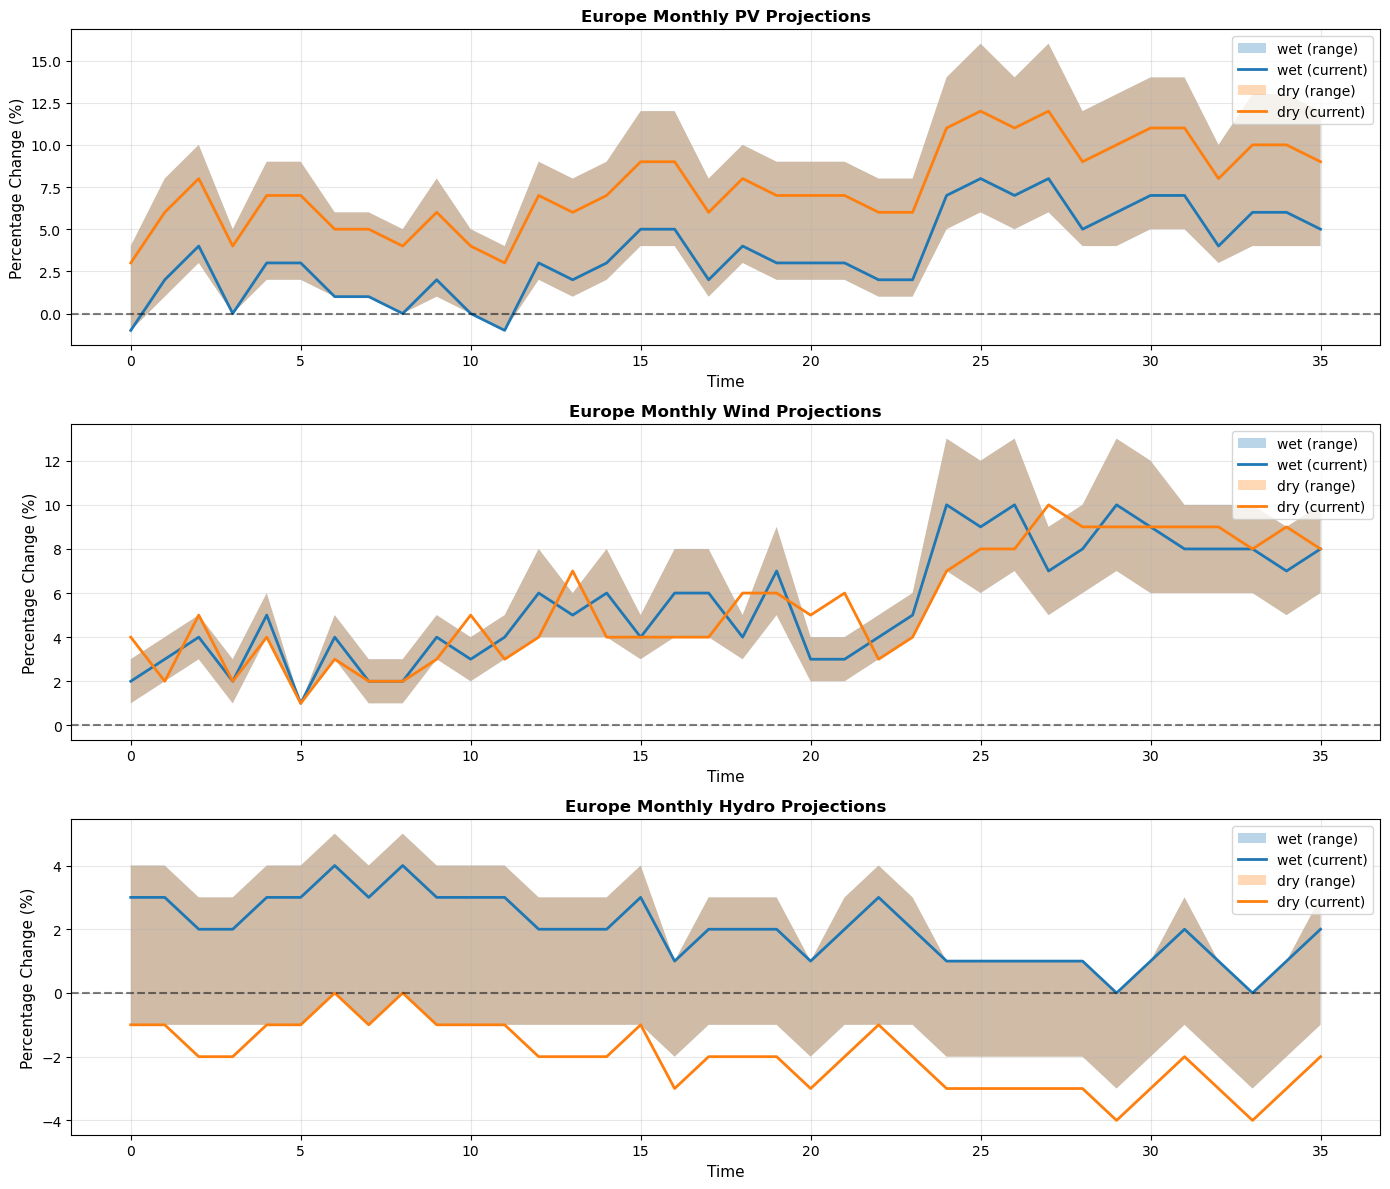

In [26]:
# Plot Europe Monthly Renewable Energy
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
techs = ['pv', 'wind', 'hydro']
titles = ['PV', 'Wind', 'Hydro']

for idx, (tech, title) in enumerate(zip(techs, titles)):
    ax = axes[idx]

    for model in ["wet", "dry"]:
        model_data = monthly_percentage_change_df[(monthly_percentage_change_df["model"] == model) &
                                                    (monthly_percentage_change_df["tech"] == tech)].copy()
        model_data["datetime"] = pd.to_datetime(model_data["time"])
        model_data = model_data.sort_values("datetime")

        # Extract min, current, max from arrays
        values = np.array([v for v in model_data["percentage_change"]])
        min_vals = values[:, 0]
        current_vals = values[:, 1]
        max_vals = values[:, 2]

        x_values = range(len(model_data))

        # Plot with fill_between for uncertainty
        ax.fill_between(x_values, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
        ax.plot(x_values, current_vals, linewidth=2, label=f'{model} (current)')

    ax.set_xlabel("Time", fontsize=11)
    ax.set_ylabel("Percentage Change (%)", fontsize=11)
    ax.set_title(f"Europe Monthly {title} Projections", fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Heating and Cooling Degree Days

In [27]:
base_temp = 18  # base temperature in Celsius

months = range(1, 13)

# Baseline projections for HDD and CDD percentage changes
# HDD decreases due to warming, CDD increases
hdd_proj = {2030: -5, 2040: -8, 2050: -12}  # percent change
cdd_proj = {2030: 10, 2040: 15, 2050: 20}   # percent change

# Monthly variation factors - HDD is higher in winter, CDD is higher in summer
# Normalized patterns (will be scaled by yearly projections)
hdd_monthly_pattern = [1.5, 1.4, 1.2, 0.8, 0.4, 0.1, 0.0, 0.0, 0.3, 0.7, 1.1, 1.4]  # Jan to Dec
cdd_monthly_pattern = [0.0, 0.0, 0.0, 0.1, 0.4, 0.9, 1.5, 1.4, 0.7, 0.2, 0.0, 0.0]  # Jan to Dec

models = ["wet", "dry"]

data = {
    "time": [],
    "area": [],
    "heating_degree_days": [],
    "cooling_degree_days": [],
    "unit": [],
    "model": []
}

for year in years:
    for i, month in enumerate(months):
        # Generate noise once per month
        hdd_noise = np.random.uniform(-1, 1)
        cdd_noise = np.random.uniform(-1, 1)

        # Apply monthly pattern to the yearly baseline
        hdd_seasonal = hdd_proj[year] * hdd_monthly_pattern[i]
        cdd_seasonal = cdd_proj[year] * cdd_monthly_pattern[i]

        # Calculate values for both models (HDD is negative, CDD is positive)
        hdd_wet = min(0, round(hdd_seasonal + 2 + hdd_noise))  # wet: less decrease
        hdd_dry = min(0, round(hdd_seasonal - 2 + hdd_noise))  # dry: more decrease
        cdd_wet = max(0, round(cdd_seasonal - 3 + cdd_noise))  # wet: less increase
        cdd_dry = max(0, round(cdd_seasonal + 3 + cdd_noise))  # dry: more increase

        # Min/max represents total model spread
        hdd_min = round(min(hdd_wet, hdd_dry) * 1.3)  # More negative
        hdd_max = round(max(hdd_wet, hdd_dry) * 0.7)  # Less negative
        cdd_min = round(min(cdd_wet, cdd_dry) * 0.7)  # Less positive
        cdd_max = round(max(cdd_wet, cdd_dry) * 1.3)  # More positive

        for model in models:
            hdd_current = hdd_wet if model == "wet" else hdd_dry
            cdd_current = cdd_wet if model == "wet" else cdd_dry

            last_day = pd.Period(f"{year}-{month}").days_in_month
            data["time"].append(f"{year}-{month:02d}-{last_day}T23:00")
            data["area"].append("europe")
            data["heating_degree_days"].append([hdd_min, hdd_current, hdd_max])
            data["cooling_degree_days"].append([cdd_min, cdd_current, cdd_max])
            data["unit"].append("%")
            data["model"].append(model)

europe_hdd_cdd_df = pd.DataFrame(data)
europe_hdd_cdd_df.to_csv("/home/yhaddad/speed2zero/website/europe_hdd_cdd_monthly.csv", index=False)

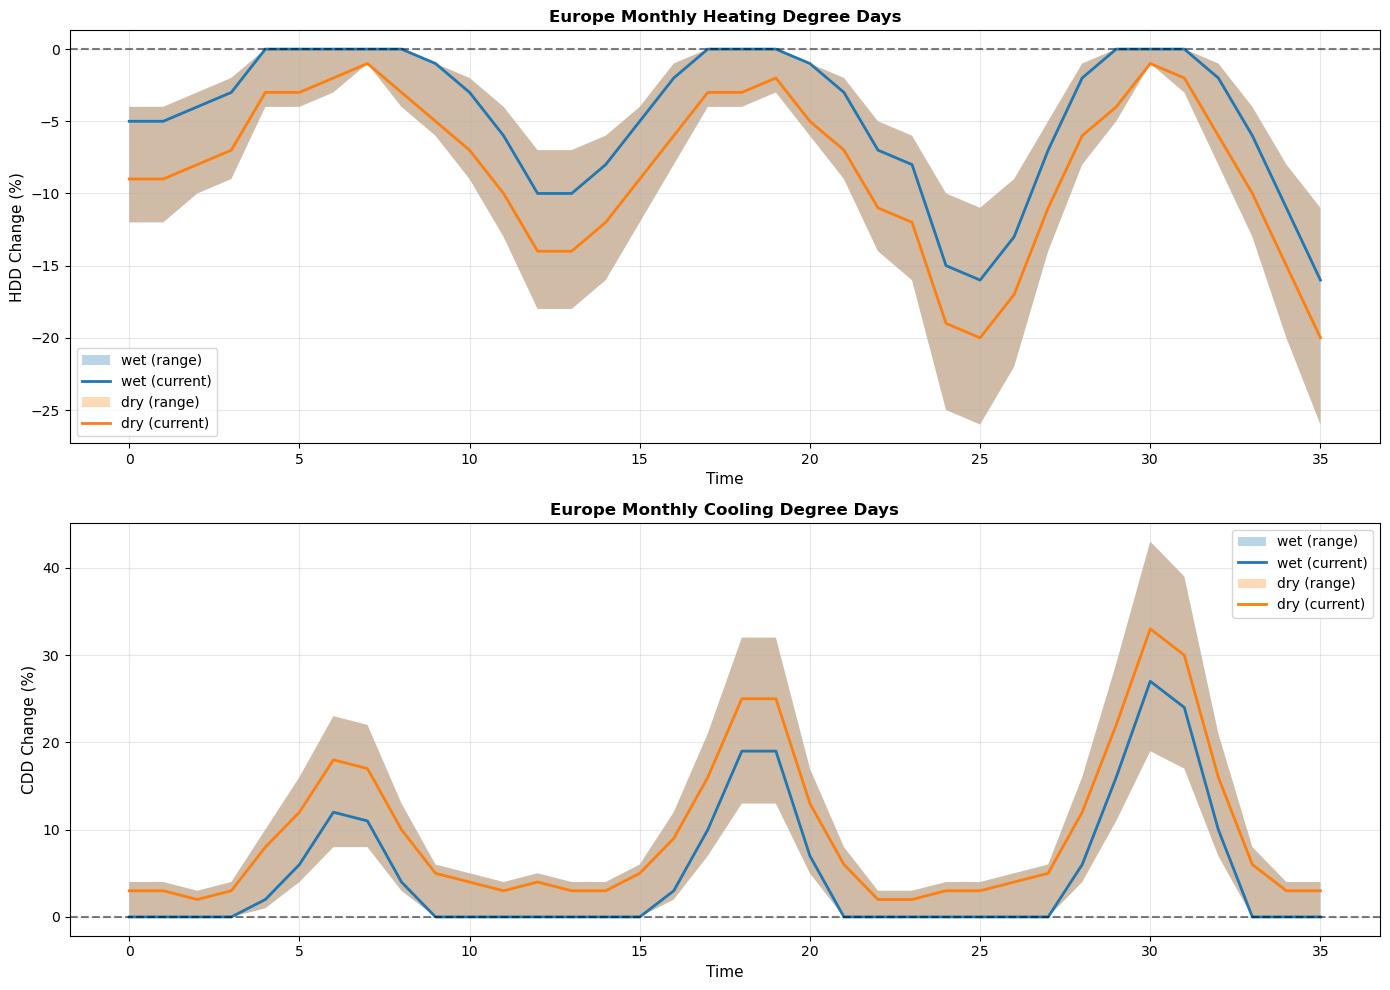

In [28]:
# Plot Europe Monthly HDD and CDD
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# HDD subplot
ax = axes[0]
for model in ["wet", "dry"]:
    model_data = europe_hdd_cdd_df[europe_hdd_cdd_df["model"] == model].copy()
    model_data["datetime"] = pd.to_datetime(model_data["time"])
    model_data = model_data.sort_values("datetime")

    # Extract min, current, max from arrays
    hdd_values = np.array([h for h in model_data["heating_degree_days"]])
    min_vals = hdd_values[:, 0]
    current_vals = hdd_values[:, 1]
    max_vals = hdd_values[:, 2]

    x_values = range(len(model_data))

    # Plot with fill_between for uncertainty
    ax.fill_between(x_values, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(x_values, current_vals, linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Time", fontsize=11)
ax.set_ylabel("HDD Change (%)", fontsize=11)
ax.set_title("Europe Monthly Heating Degree Days", fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

# CDD subplot
ax = axes[1]
for model in ["wet", "dry"]:
    model_data = europe_hdd_cdd_df[europe_hdd_cdd_df["model"] == model].copy()
    model_data["datetime"] = pd.to_datetime(model_data["time"])
    model_data = model_data.sort_values("datetime")

    # Extract min, current, max from arrays
    cdd_values = np.array([c for c in model_data["cooling_degree_days"]])
    min_vals = cdd_values[:, 0]
    current_vals = cdd_values[:, 1]
    max_vals = cdd_values[:, 2]

    x_values = range(len(model_data))

    # Plot with fill_between for uncertainty
    ax.fill_between(x_values, min_vals, max_vals, alpha=0.3, label=f'{model} (range)')
    ax.plot(x_values, current_vals, linewidth=2, label=f'{model} (current)')

ax.set_xlabel("Time", fontsize=11)
ax.set_ylabel("CDD Change (%)", fontsize=11)
ax.set_title("Europe Monthly Cooling Degree Days", fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# README

In [29]:
readme_md = """
# README

These are dummy datasets for Europe and Switzerland, simulating climate and renewable energy projections for the years 2030, 2040, and 2050. All relative quantities (anomalies, percentage changes) are relative to the 1991-2020 reference period, used as baseline.

All datasets include a **model** column with two climate scenarios:
- **wet**: Cooler temperatures (-0.3°C), lower PV (-2%), higher hydro (+2%)
- **dry**: Warmer temperatures (+0.3°C), higher PV (+2%), lower hydro (-2%)

All numeric values (temperature, percentage_change, heating/cooling degree days) are stored as **arrays with three elements**: `[min, current, max]`, where min = current × 0.6 and max = current × 1.4.

---

## Europe

### Yearly

#### 1. `europe_temperature_per_country_yearly.csv`
- **Columns:** `time`, `area`, `location`, `temperature`, `unit`, `model`
- **Description:** Decadal temperature anomaly for each European country.
- **Example row:**
    `2030-12-31T23:00, europe, France, "[1.44, 1.8, 2.16]", c, dry`

#### 2. `europe_temperature_yearly.csv`
- **Columns:** `time`, `area`, `temperature`, `unit`, `model`
- **Description:** Decadal average temperature anomaly for Europe as a whole.
- **Example row:**
    `2040-12-31T23:00, europe, "[1.76, 2.2, 2.64]", c, wet`

#### 3. `europe_percentage_change_yearly.csv`
- **Columns:** `time`, `area`, `tech`, `percentage_change`, `unit`, `model`
- **Description:** Decadal projected percent change in renewable energy generation (PV, wind, hydro) for Europe.
- **tech values:** `pv`, `wind`, `hydro`
- **Example rows:**
    - `2050-12-31T23:00, europe, pv, "[8, 10, 12]", %, dry`
    - `2040-12-31T23:00, europe, wind, "[4, 5, 6]", %, wet`
    - `2030-12-31T23:00, europe, hydro, "[-3.2, -4, -4.8]", %, dry`

#### 4. `europe_hdd_cdd_yearly.csv`
- **Columns:** `time`, `area`, `heating_degree_days`, `cooling_degree_days`, `unit`, `model`
- **Description:** Decadal percent change in heating and cooling degree days for Europe.
- **Note:** Values represent percentage changes from baseline. HDD decreases (negative values) and CDD increases (positive values) due to warming. Dry model has larger HDD decrease (-2%) and larger CDD increase (+3%); wet model has smaller changes (+2% HDD, -3% CDD).
- **Example row:**
    `2050-12-31T23:00, europe, "[-11, -14, -17]", "[18, 23, 28]", %, dry`

### Monthly

#### 5. `europe_percentage_change_monthly.csv`
- **Columns:** `time`, `area`, `tech`, `percentage_change`, `unit`, `model`
- **Description:** Decadal monthly projected percent change in renewable energy generation (PV, wind, hydro) for Europe.
- **tech values:** `pv`, `wind`, `hydro`
- **Example row:**
    `2050-06-30T23:00, europe, pv, "[9, 11, 13]", %, wet`

#### 6. `europe_hdd_cdd_monthly.csv`
- **Columns:** `time`, `area`, `heating_degree_days`, `cooling_degree_days`, `unit`, `model`
- **Description:** Decadal monthly percent change in heating and cooling degree days for Europe with seasonal variation.
- **Note:** Values represent percentage changes from baseline and vary by month. HDD is highest in winter months (Jan-Mar, Dec) and near zero in summer (Jul-Aug). CDD is highest in summer months (Jun-Aug) and zero in winter. Dry model has larger HDD decrease (-2%) and larger CDD increase (+3%); wet model has smaller changes (+2% HDD, -3% CDD).
- **Monthly pattern:**
  - **HDD:** Winter (1.4-1.5×), Spring (0.4-1.2×), Summer (0.0×), Fall (0.3-1.1×) relative to yearly baseline
  - **CDD:** Winter (0.0×), Spring (0.1-0.4×), Summer (0.9-1.5×), Fall (0.2-0.7×) relative to yearly baseline
- **Example rows:**
    - `2050-01-31T23:00, europe, "[-16, -20, -24]", "[0, 0, 0]", %, dry` (winter - high HDD, no CDD)
    - `2050-07-31T23:00, europe, "[0, 0, 0]", "[29, 36, 43]", %, dry` (summer - no HDD, high CDD)

---

## Switzerland

### Yearly

#### 1. `switzerland_temperature_per_canton_yearly.csv`
- **Columns:** `time`, `area`, `location`, `temperature`, `unit`, `model`
- **Description:** Decadal average temperature anomaly for each canton in Switzerland.
- **Example row:**
    `2040-12-31T23:00, switzerland, Geneva, "[2.0, 2.5, 3.0]", c, wet`

#### 2. `switzerland_temperature_yearly.csv`
- **Columns:** `time`, `area`, `temperature`, `unit`, `model`
- **Description:** Decadal average temperature anomaly for Switzerland.
- **Example row:**
    `2040-12-31T23:00, switzerland, "[2.0, 2.5, 3.0]", c, dry`

#### 3. `switzerland_percentage_change_yearly.csv`
- **Columns:** `time`, `area`, `tech`, `percentage_change`, `unit`, `model`
- **Description:** Decadal projected percent change in renewable energy generation (PV, wind, hydro) for Switzerland.
- **tech values:** `pv`, `wind`, `hydro`
- **Example rows:**
    - `2050-12-31T23:00, switzerland, pv, "[6, 8, 10]", %, dry`
    - `2030-12-31T23:00, switzerland, wind, "[4, 5, 6]", %, wet`
    - `2040-12-31T23:00, switzerland, hydro, "[-0.8, -1, -1.2]", %, wet`

#### 4. `switzerland_hdd_cdd_yearly.csv`
- **Columns:** `time`, `area`, `heating_degree_days`, `cooling_degree_days`, `unit`, `model`
- **Description:** Decadal percent change in heating and cooling degree days for Switzerland.
- **Note:** Values represent percentage changes from baseline. HDD decreases (negative values) and CDD increases (positive values) due to warming. Dry model has larger HDD decrease (-2%) and larger CDD increase (+3%); wet model has smaller changes (+2% HDD, -3% CDD).
- **Example row:**
    `2040-12-31T23:00, switzerland, "[-6, -8, -10]", "[10, 13, 16]", %, wet`

### Monthly

#### 5. `switzerland_percentage_change_monthly.csv`
- **Columns:** `time`, `area`, `tech`, `percentage_change`, `unit`, `model`
- **Description:** Decadal monthly projected percent change in renewable energy generation (PV, wind, hydro) for Switzerland.
- **tech values:** `pv`, `wind`, `hydro`
- **Example row:**
    `2040-07-31T23:00, switzerland, hydro, "[1, 1, 1]", %, dry`

#### 6. `switzerland_hdd_cdd_monthly.csv`
- **Columns:** `time`, `area`, `heating_degree_days`, `cooling_degree_days`, `unit`, `model`
- **Description:** Decadal monthly percent change in heating and cooling degree days for Switzerland with seasonal variation.
- **Note:** Values represent percentage changes from baseline and vary by month. HDD is highest in winter months (Jan-Mar, Dec) and near zero in summer (Jul-Aug). CDD is highest in summer months (Jun-Aug) and zero in winter. Dry model has larger HDD decrease (-2%) and larger CDD increase (+3%); wet model has smaller changes (+2% HDD, -3% CDD).
- **Monthly pattern:**
  - **HDD:** Winter (1.4-1.5×), Spring (0.4-1.2×), Summer (0.0×), Fall (0.3-1.1×) relative to yearly baseline
  - **CDD:** Winter (0.0×), Spring (0.1-0.4×), Summer (0.9-1.5×), Fall (0.2-0.7×) relative to yearly baseline
- **Example rows:**
    - `2040-02-29T23:00, switzerland, "[-9, -11, -13]", "[0, 0, 0]", %, wet` (winter - high HDD, no CDD)
    - `2040-07-31T23:00, switzerland, "[0, 0, 0]", "[13, 16, 19]", %, wet` (summer - no HDD, high CDD)

---

## Data Format Notes

### Columns

- **time:** ISO 8601 format (`YYYY-MM-DDTHH:MM`)
- **area:** `europe` or `switzerland`
- **location:** Canton (Switzerland) or country (Europe) - only in per-location datasets
- **temperature:** Array `[min, current, max]` - simulated temperature anomaly in °C
- **tech:** Technology type - `pv` (solar photovoltaic), `wind` (wind power), or `hydro` (hydropower)
- **percentage_change:** Array `[min, current, max]` - simulated percent change in power generation
- **heating_degree_days / cooling_degree_days:** Array `[min, current, max]` - percent change values (negative for HDD decrease, positive for CDD increase)
- **unit:** `c` for Celsius, `%` for percent change
- **model:** `wet` or `dry` climate scenario

### Model Variations

**Dry Model** (warmer, less precipitation):
- Temperature: +0.3°C adjustment
- PV: +2% (more sunshine)
- Wind: no adjustment
- Hydro: -2% (less precipitation/runoff)
- HDD: -2% additional decrease (less heating needed)
- CDD: +3% additional increase (more cooling needed)

**Wet Model** (cooler, more precipitation):
- Temperature: -0.3°C adjustment
- PV: -2% (more clouds)
- Wind: no adjustment
- Hydro: +2% (more precipitation/runoff)
- HDD: +2% adjustment (less decrease, more heating needed)
- CDD: -3% adjustment (less increase, less cooling needed)

### Value Ranges

All numeric values are represented as arrays with three values:
- **min**: current value × 0.6 (-40%)
- **current**: the simulated value
- **max**: current value × 1.4 (+40%)

### Heating and Cooling Degree Days

HDD and CDD values represent **percentage changes** from the 1991-2020 baseline:
- **Heating Degree Days (HDD):** Expected to decrease (negative values) as temperatures rise and less heating is required
- **Cooling Degree Days (CDD):** Expected to increase (positive values) as temperatures rise and more cooling is required
- **Yearly baseline projections:**
  - 2030: -5% HDD, +10% CDD
  - 2040: -8% HDD, +15% CDD
  - 2050: -12% HDD, +20% CDD

- **Monthly variation:** Monthly values are calculated by multiplying the yearly baseline by seasonal patterns:
  - **HDD monthly factors:** [1.5, 1.4, 1.2, 0.8, 0.4, 0.1, 0.0, 0.0, 0.3, 0.7, 1.1, 1.4] for Jan-Dec
    - Highest in winter (Jan: 1.5×, Feb: 1.4×, Dec: 1.4×)
    - Zero in summer (Jul-Aug: 0.0×)
  - **CDD monthly factors:** [0.0, 0.0, 0.0, 0.1, 0.4, 0.9, 1.5, 1.4, 0.7, 0.2, 0.0, 0.0] for Jan-Dec
    - Zero in winter (Jan-Mar, Nov-Dec: 0.0×)
    - Highest in summer (Jul: 1.5×, Aug: 1.4×)

This creates realistic seasonal patterns where:
- Winter months have the largest HDD decreases and zero CDD changes
- Summer months have zero HDD changes and the largest CDD increases
- Spring and fall show intermediate values

---

## Summary of Files

**Total: 12 CSV files**

**Europe (6 files):**
1. `europe_temperature_per_country_yearly.csv` - Temperature by country (yearly)
2. `europe_temperature_yearly.csv` - Temperature for all Europe (yearly)
3. `europe_percentage_change_yearly.csv` - Renewable energy changes (yearly)
4. `europe_hdd_cdd_yearly.csv` - Heating/cooling degree days (yearly)
5. `europe_percentage_change_monthly.csv` - Renewable energy changes (monthly)
6. `europe_hdd_cdd_monthly.csv` - Heating/cooling degree days with seasonal variation (monthly)

**Switzerland (6 files):**
1. `switzerland_temperature_per_canton_yearly.csv` - Temperature by canton (yearly)
2. `switzerland_temperature_yearly.csv` - Temperature for all Switzerland (yearly)
3. `switzerland_percentage_change_yearly.csv` - Renewable energy changes (yearly)
4. `switzerland_hdd_cdd_yearly.csv` - Heating/cooling degree days (yearly)
5. `switzerland_percentage_change_monthly.csv` - Renewable energy changes (monthly)
6. `switzerland_hdd_cdd_monthly.csv` - Heating/cooling degree days with seasonal variation (monthly)

---

## Important Notes

All data is **randomly generated for demonstration purposes** and does not represent real-world measurements or actual climate model projections. The relationships between variables (e.g., dry = higher temps & higher PV) are simplified for illustrative purposes.
"""

with open("/home/yhaddad/speed2zero/website/README.md", "w") as f:
        f.write(readme_md)